# 14 — FrozenLake Dyna-DQN

Neural Q 추정과 관측 기반 Tabular World Model을 조합한다. 원시 정수 State ID를 저장하고 Model 내부의
고정 One-hot Representation 뒤에서 MLP가 학습한다. Real Replay와 Planning 1-step은 같은 Online/Target/Adam을 사용한다.
이 World Model은 연속 관측을 예측하지 못하므로 CartPole Dyna-DQN으로 소개하지 않는다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation, MLPRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator, DiscreteQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator, NStepTargetGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule, TDLossUpdateRule
from modular_rl.component.buffer import ReplayBuffer, SequenceReplayBuffer
from modular_rl.data import Transition, Episode
from modular_rl.learner import (TabularQLearner, TabularSARSALearner, TabularTD0PredictionLearner,
    MCPredictionLearner, TabularMCControlLearner, OffPolicyMCPredictionLearner, OffPolicyMCControlLearner, DQNLearner)
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
S, A = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
representation = nn.Sequential(nn.Embedding.from_pretrained(torch.eye(S), freeze=True),
                               MLPRepresentation(S, hidden_dims=(64,64)))
estimator = DiscreteQEstimator(64,A)
selector = EpsilonGreedyActionSelector(1.)
model = Model(representation, estimator, selector)
target_model = deepcopy(model)
optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=.001)
target_generator = TD0TargetGenerator(GAMMA)
update_rule = TDLossUpdateRule(nn.SmoothL1Loss(reduction='none'))
learner = DQNLearner(model, target_model, optimizer, target_generator, update_rule)
learner.sync_target()

from examples.gridworld_dyna_q import TabularWorldModel
from examples.gridworld_dyna_dqn import plan
world = TabularWorldModel()
planning_rng = np.random.default_rng(SEED+3)
buffer = ReplayBuffer(5000, seed=SEED)
BATCH_SIZE, WARMUP = (8,16) if FAST else (32,64)
log, losses = history(), []
steps = real_updates = planning_updates = 0

In [4]:
for episode_index in range(25 if FAST else 1000):
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    total, length = 0., 0
    while True:
        selector.epsilon = max(.05, 1.-steps/(500 if FAST else 6000))
        selected = model.act(observation)
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        buffer.add(observation, selected.action, reward, next_observation, terminated, truncated)
        if len(buffer) >= WARMUP:
            result = learner.learn(buffer.sample(BATCH_SIZE))
            losses.append(result.loss.item()); real_updates += 1
        world.observe(Transition(observation, selected.action.item(), reward, next_observation, terminated, truncated))
        planned = plan(world, learner, steps=1, batch_size=BATCH_SIZE, rng=planning_rng)
        planning_updates += planned['updates']
        steps += 1; total += reward; length += 1
        if steps % 100 == 0: learner.sync_target()  # 실제 환경 step 스케줄
        observation = next_observation
        if terminated or truncated: break
    record(log, total, length, terminated, truncated)
print({'real_updates':real_updates,'planning_updates':planning_updates,'observed_pairs':len(world)})

{'real_updates': 260, 'planning_updates': 275, 'observed_pairs': 25}


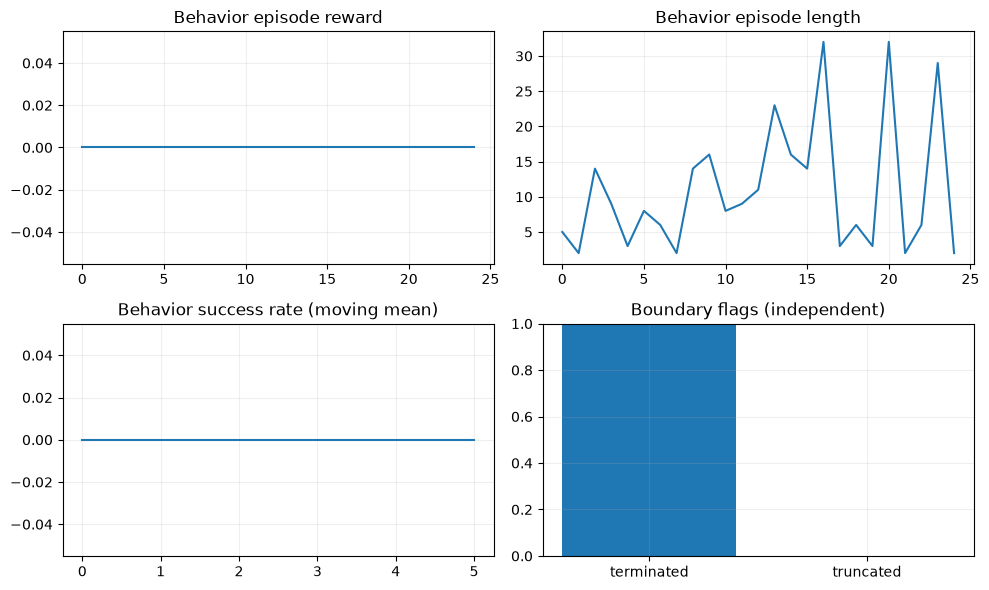

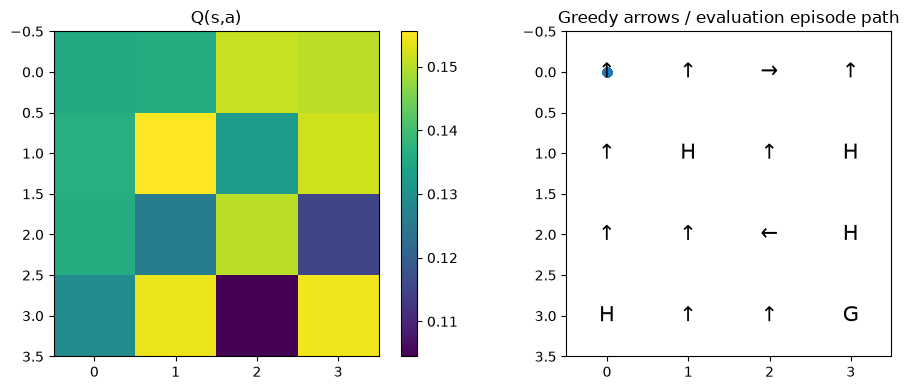

Q(s,a) [[ 0.1347  0.1355  0.1351  0.1355]
 [ 0.1352 -0.0007  0.1347  0.136 ]
 [ 0.1347  0.145   0.1513  0.1343]
 [ 0.1329 -0.0006  0.0766  0.1503]
 [ 0.1315  0.1338  0.0018  0.1364]
 [ 0.1025  0.0253  0.0452  0.1555]
 [ 0.0259  0.0689  0.0032  0.1325]
 [ 0.1053  0.059   0.1001  0.1518]
 [ 0.134  -0.001   0.0808  0.1361]
 [ 0.1142  0.089   0.1009  0.1259]
 [ 0.1502  0.087   0.1257  0.138 ]
 [ 0.0836  0.1151  0.0868  0.1143]
 [ 0.0852  0.0825  0.1058  0.1292]
 [ 0.1397  0.0752  0.068   0.1541]
 [ 0.0695  0.0775  0.0612  0.1045]
 [ 0.1021  0.0625  0.1149  0.1544]]
RESULT {"environment_steps": 275, "episodes": 25, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [5]:
model.eval()
evaluation = evaluate(eval_env, lambda state: model.act(state, deterministic=True).action.item(), episodes=5 if FAST else 100, seed=SEED+1000)
table = model(torch.arange(S)).values.q[0].detach().numpy()
greedy_actions = table.argmax(-1)
summary = frozen_report(desc, log, table, evaluation, greedy_actions=greedy_actions, label='Q(s,a)')
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
Buffer에는 정수 ID, Model에는 One-hot + MLP를 연결한다. Planning이 Replay를 더 채우거나 환경 step을 증가시키지 않는다. TabularWorldModel/plan은 예제 지원이며 새 World Model 추상 계층은 만들지 않는다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.